# Full Embedding Model Comparison: Nemotron-8B vs All Existing Models
## nvidia/llama-embed-nemotron-8b vs V4 Cosine (Production) vs MPNet vs SimCSE Unsupervised vs Baselines

**Objective**: Determine whether `nvidia/llama-embed-nemotron-8b` should replace our V4 Cosine production model.

**Models tested**:
| Group | Model | Dims | Notes |
|-------|-------|------|-------|
| 🏆 Production | V4 Cosine (MPNet LoRA r=16) | 768 | Current production — baseline to beat |
| 🆕 Challenger | Nemotron-8B | 4096 | Full native dim |
| 🆕 Challenger | Nemotron-8B (truncated) | 768 | Matryoshka-style truncation |
| 📊 Supervised | MPNet LoRA variants | 768 | 4 best checkpoints |
| 🔬 Unsupervised | SimCSE (best runs) | 768 | Best hard-negative SimCSE |
| 📌 Baselines | all-mpnet-base-v2 | 768 | Raw MPNet — no fine-tuning |
| 📌 Baselines | all-MiniLM-L6-v2 | 384 | Fast baseline |
| 📌 Baselines | EmbeddingGemma-300M | 384 | Google baseline |

**Hardware**: RTX 5090 (32GB VRAM)

**Evaluation**: Spearman, ROC-AUC, F1, Precision, Recall, Adversarial ROC-AUC, Inference Latency

**Decision threshold**: Switch to Nemotron if ROC-AUC ≥ 0.800 AND latency is acceptable


## ⚡ Quick Start — Run Cells in This Order

> **Cell execution order:**
> 1. Cell 2 — GPU Setup
> 2. Cell 3 — Configuration
> 3. Cell 4 — Imports & Utilities
> 4. Cell 5 — Load Test Data
> 5. Cell 6 — Model Loader
> 6. **Cell 13 — HuggingFace Auth** ← run this before main eval if testing Nemotron
> 7. **Cell 7 — Main Evaluation Loop** ← this runs all models (takes ~30–60 min)
> 8. Cells 8–12 — Clustering, Visualization, Comparison, Decision Matrix

**Prerequisites:** `pip install umap-learn hdbscan` (if not already installed)


## 1. GPU Setup & Verification

In [13]:
import torch
import os

# Confirm GPU
assert torch.cuda.is_available(), "CUDA not available! This notebook requires a GPU."

device = 'cuda'
gpu_name = torch.cuda.get_device_name(0)
vram_gb = torch.cuda.get_device_properties(0).total_memory / 1e9

print(f"GPU:        {gpu_name}")
print(f"VRAM:       {vram_gb:.1f} GB")
print(f"CUDA:       {torch.version.cuda}")
print(f"PyTorch:    {torch.__version__}")
print(f"cuDNN:      {torch.backends.cudnn.version()}")

# Prevent fragmentation
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

# Quick tensor round-trip to confirm RTX is active
x = torch.randn(4096, 4096, device=device)
y = x @ x.T
torch.cuda.synchronize()
del x, y
print(f"\nGPU tensor ops: OK (4096x4096 matmul)")
print(f"Ready for evaluation.")


GPU:        NVIDIA GeForce RTX 5090
VRAM:       34.2 GB
CUDA:       13.0
PyTorch:    2.9.1+cu130
cuDNN:      91200

GPU tensor ops: OK (4096x4096 matmul)
Ready for evaluation.


## 2. Configuration — Edit All Settings Here

In [14]:
from pathlib import Path

# ── Paths ──────────────────────────────────────────────────────────────────
PROJECT_ROOT   = Path.cwd()
DATA_DIR       = PROJECT_ROOT / 'data_new'
MODELS_DIR     = PROJECT_ROOT / 'models'
RESULTS_DIR    = MODELS_DIR  / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TEST_PAIRS_FILE = 'fixed_test_pairs.json'
INCIDENT_CSV    = 'SNow_incident_ticket_data.csv'

# ── Supervised test pairs evaluation models ────────────────────────────────
# Key: display name, Value: config dict
SUPERVISED_MODELS = {

    # ── Baselines ──────────────────────────────────────────────────────────
    'MPNet-Base (raw)': {
        'type': 'sentence_transformer',
        'model_id': 'sentence-transformers/all-mpnet-base-v2',
        'batch_size': 128,
        'truncate_dim': None,
        'trust_remote_code': False,
    },
    'MiniLM-L6-v2': {
        'type': 'sentence_transformer',
        'model_id': 'sentence-transformers/all-MiniLM-L6-v2',
        'batch_size': 256,
        'truncate_dim': None,
        'trust_remote_code': False,
    },
    'EmbeddingGemma-300M': {
        'type': 'sentence_transformer',
        'model_id': 'google/embeddinggemma-300m',
        'batch_size': 64,
        'truncate_dim': None,
        'trust_remote_code': True,
    },

    # ── Local fine-tuned MPNet LoRA checkpoints ───────────────────────────
    'V4-Cosine [PRODUCTION]': {
        'type': 'lora_peft',
        'base_model': 'sentence-transformers/all-mpnet-base-v2',
        'adapter_path': str(MODELS_DIR / 'real_servicenow_finetuned_mpnet_lora/real_servicenow_v2_20260104_2321'),
        'batch_size': 128,
        'truncate_dim': None,
    },
    'MPNet-LoRA Phase3-Only': {
        'type': 'lora_peft',
        'base_model': 'sentence-transformers/all-mpnet-base-v2',
        'adapter_path': str(MODELS_DIR / 'real_servicenow_finetuned_mpnet_lora/phase3_only_20260101_1238'),
        'batch_size': 128,
        'truncate_dim': None,
    },
    'MPNet-LoRA MNRL-2322': {
        'type': 'lora_peft',
        'base_model': 'sentence-transformers/all-mpnet-base-v2',
        'adapter_path': str(MODELS_DIR / 'real_servicenow_finetuned_mpnet_lora/real_servicenow_v2_20251227_0214'),
        'batch_size': 128,
        'truncate_dim': None,
    },
    'MPNet-LoRA Expanded-Data': {
        'type': 'lora_peft',
        'base_model': 'sentence-transformers/all-mpnet-base-v2',
        'adapter_path': str(MODELS_DIR / 'real_servicenow_finetuned_mpnet_lora/real_servicenow_v2_20251228_0418'),
        'batch_size': 128,
        'truncate_dim': None,
    },

    # ── Unsupervised SimCSE ────────────────────────────────────────────────
    'SimCSE-HardNeg (best)': {
        'type': 'sentence_transformer',
        'model_id': str(MODELS_DIR / 'unsupervised_simcse/simcse_20260212_091123_hardneg'),
        'batch_size': 128,
        'truncate_dim': None,
        'trust_remote_code': False,
    },
    'SimCSE-Standard (best)': {
        'type': 'sentence_transformer',
        'model_id': str(MODELS_DIR / 'unsupervised_simcse/simcse_20260212_091123'),
        'batch_size': 128,
        'truncate_dim': None,
        'trust_remote_code': False,
    },
    'SimCSE-Feb12-v1': {
        'type': 'sentence_transformer',
        'model_id': str(MODELS_DIR / 'unsupervised_simcse/simcse_20260212_084052'),
        'batch_size': 128,
        'truncate_dim': None,
        'trust_remote_code': False,
    },

    # ── Nemotron-8B challenger ─────────────────────────────────────────────
    'Nemotron-8B (4096-dim)': {
        'type': 'nemotron',
        'model_id': 'nvidia/llama-embed-nemotron-8b',
        'batch_size': 4,       # 8B fp16 ~16GB; batch=4×512tok is safe on 32GB
        'truncate_dim': None,
        'trust_remote_code': True,
        'instruction': 'Instruct: Given an IT incident description, retrieve similar incidents\nQuery: ',
    },
    'Nemotron-8B (768-dim)': {
        'type': 'nemotron',
        'model_id': 'nvidia/llama-embed-nemotron-8b',
        'batch_size': 4,
        'truncate_dim': 768,
        'trust_remote_code': True,
        'instruction': 'Instruct: Given an IT incident description, retrieve similar incidents\nQuery: ',
    },
}

# ── Evaluation settings ────────────────────────────────────────────────────
RANDOM_SEED         = 42
NUM_THRESHOLDS      = 100
MIN_TEXT_LENGTH     = 10
NUM_BENCHMARK_RUNS  = 3
ENABLE_CLUSTERING   = True
CLUSTER_SAMPLE_SIZE = 800   # subset for clustering (speed)
KMEANS_K            = 10

print("Configuration loaded.")
print(f"  Test data:     {DATA_DIR / TEST_PAIRS_FILE}")
print(f"  Models to run: {len(SUPERVISED_MODELS)}")
print(f"  Results dir:   {RESULTS_DIR}")


Configuration loaded.
  Test data:     c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data_new\fixed_test_pairs.json
  Models to run: 12
  Results dir:   c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\results


## 3. Imports & Utility Functions

In [15]:
import gc
import json
import random
import time
import warnings
from datetime import datetime
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import scipy.stats as stats
from sklearn.metrics import (roc_auc_score, f1_score, precision_score,
                              recall_score, accuracy_score, confusion_matrix,
                              silhouette_score, davies_bouldin_score,
                              adjusted_rand_score, normalized_mutual_info_score)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
import torch
from sentence_transformers import SentenceTransformer
warnings.filterwarnings('ignore')

# ── Reproducibility ─────────────────────────────────────────────────────────
def set_seeds(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seeds(RANDOM_SEED)

# ── GPU helpers ──────────────────────────────────────────────────────────────
def gpu_free_gb() -> float:
    if torch.cuda.is_available():
        free, total = torch.cuda.mem_get_info()
        return free / 1e9
    return 0.0

def gpu_used_gb() -> float:
    if torch.cuda.is_available():
        return torch.cuda.memory_allocated() / 1e9
    return 0.0

def cleanup_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.synchronize()

# ── Metrics ──────────────────────────────────────────────────────────────────
def find_optimal_threshold(labels: np.ndarray, scores: np.ndarray,
                            n: int = 100) -> Tuple[float, float]:
    thresholds = np.linspace(scores.min(), scores.max(), n)
    best_t, best_f1 = 0.5, 0.0
    for t in thresholds:
        preds = (scores >= t).astype(int)
        f1 = f1_score(labels, preds, zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    return best_t, best_f1

def compute_all_metrics(labels: np.ndarray, scores: np.ndarray) -> Dict:
    threshold, _ = find_optimal_threshold(labels, scores, NUM_THRESHOLDS)
    preds = (scores >= threshold).astype(int)
    spearman_r, _ = stats.spearmanr(labels, scores)
    try:
        roc_auc = roc_auc_score(labels, scores)
    except Exception:
        roc_auc = float('nan')
    return {
        'spearman':     float(spearman_r),
        'roc_auc':      float(roc_auc),
        'f1':           float(f1_score(labels, preds, zero_division=0)),
        'precision':    float(precision_score(labels, preds, zero_division=0)),
        'recall':       float(recall_score(labels, preds, zero_division=0)),
        'accuracy':     float(accuracy_score(labels, preds)),
        'threshold':    float(threshold),
        'confusion_matrix': confusion_matrix(labels, preds).tolist(),
    }

def compute_adversarial_auc(labels: np.ndarray, scores: np.ndarray,
                              emb1: np.ndarray, emb2: np.ndarray,
                              pct: float = 0.3) -> float:
    """Recompute ROC-AUC on hardest negatives (lowest cosine among true negatives)."""
    neg_mask = labels == 0
    if neg_mask.sum() < 10:
        return float('nan')
    neg_scores = scores[neg_mask]
    cutoff = np.percentile(neg_scores, pct * 100)
    hard_neg_mask = neg_mask & (scores <= cutoff)
    pos_mask = labels == 1
    combined_mask = hard_neg_mask | pos_mask
    if combined_mask.sum() < 10:
        return float('nan')
    try:
        return float(roc_auc_score(labels[combined_mask], scores[combined_mask]))
    except Exception:
        return float('nan')

print("Imports and utility functions ready.")
print(f"GPU free: {gpu_free_gb():.1f} GB")


Imports and utility functions ready.
GPU free: 32.2 GB


## 4. Load Test Data

In [16]:
# ── Load supervised test pairs ───────────────────────────────────────────────
test_pairs_path = DATA_DIR / TEST_PAIRS_FILE
print(f"Loading test pairs from: {test_pairs_path}")

with open(test_pairs_path, 'r', encoding='utf-8') as f:
    raw = json.load(f)

if isinstance(raw, dict) and 'texts1' in raw:
    test_texts1 = raw['texts1']
    test_texts2 = raw['texts2']
    test_labels = np.array(raw['labels'])
elif isinstance(raw, list):
    test_texts1 = [p['text1'] for p in raw]
    test_texts2 = [p['text2'] for p in raw]
    test_labels = np.array([p['label'] for p in raw])
else:
    raise ValueError("Unexpected format in test pairs file.")

# Filter out very short texts
valid = [(len(t1) >= MIN_TEXT_LENGTH and len(t2) >= MIN_TEXT_LENGTH)
         for t1, t2 in zip(test_texts1, test_texts2)]
test_texts1 = [t for t, v in zip(test_texts1, valid) if v]
test_texts2 = [t for t, v in zip(test_texts2, valid) if v]
test_labels  = test_labels[valid]

n_pos = int(test_labels.sum())
n_neg = int((1 - test_labels).sum())

print(f"\nTest pairs loaded:")
print(f"  Total:    {len(test_labels)}")
print(f"  Positive: {n_pos}  ({100*n_pos/len(test_labels):.1f}%)")
print(f"  Negative: {n_neg}  ({100*n_neg/len(test_labels):.1f}%)")
print(f"  Example text1[0]: '{test_texts1[0][:80]}...'")

# ── Load incident corpus for clustering ──────────────────────────────────────
corpus_path = DATA_DIR / INCIDENT_CSV
if corpus_path.exists():
    df_corpus = pd.read_csv(corpus_path)

    # Normalise column names to lower with underscores for safe access
    df_corpus.columns = df_corpus.columns.str.strip().str.lower().str.replace(' ', '_')
    print(f"\nCSV columns: {list(df_corpus.columns)}")

    # Build a single text column — adapt to actual column names
    # Primary: 'description'; Secondary: 'user_input' (short summary field)
    desc_col   = next((c for c in df_corpus.columns if 'description' in c and 'short' not in c), None)
    short_col  = next((c for c in df_corpus.columns if 'user_input' in c or 'short_desc' in c), None)
    cat_col    = next((c for c in df_corpus.columns if 'category' in c and 'sub' not in c), None)

    if desc_col is None:
        raise ValueError(f"No description column found. Available: {list(df_corpus.columns)}")

    if short_col:
        corpus_texts = (
            df_corpus[short_col].fillna('') + ' ' +
            df_corpus[desc_col].fillna('')
        ).str.strip().tolist()
    else:
        corpus_texts = df_corpus[desc_col].fillna('').str.strip().tolist()

    print(f"  Using description col: '{desc_col}'")
    print(f"  Using short/input col: '{short_col}'")
    print(f"  Using category col:    '{cat_col}'")

    # Filter empties
    corpus_texts = [t for t in corpus_texts if len(t) >= MIN_TEXT_LENGTH]

    # Sample for clustering speed
    rng = np.random.default_rng(RANDOM_SEED)
    cluster_idx = rng.choice(len(corpus_texts), size=min(CLUSTER_SAMPLE_SIZE, len(corpus_texts)), replace=False)
    cluster_texts = [corpus_texts[i] for i in cluster_idx]

    # Category labels (if available) for ARI/NMI
    if cat_col:
        df_cluster = df_corpus.iloc[cluster_idx].reset_index(drop=True)
        cluster_labels_true = pd.Categorical(df_cluster[cat_col]).codes
    else:
        cluster_labels_true = None

    print(f"\nCorpus loaded from {corpus_path.name}:")
    print(f"  Total incidents: {len(corpus_texts)}")
    print(f"  Cluster sample:  {len(cluster_texts)}")
    if cluster_labels_true is not None:
        print(f"  Category classes: {len(set(cluster_labels_true))}")
else:
    corpus_texts = None
    cluster_texts = None
    cluster_labels_true = None
    print("\nCorpus CSV not found — clustering will be skipped.")


Loading test pairs from: c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data_new\fixed_test_pairs.json

Test pairs loaded:
  Total:    1000
  Positive: 500  (50.0%)
  Negative: 500  (50.0%)
  Example text1[0]: 'INC0020661 Please help to check error when we do CO44 processing for plant RIFW....'

CSV columns: ['number', 'description', 'opened_by', 'company', 'itsm_department', 'created', 'urgency', 'impact', 'priority', 'assignment_group', 'assigned_to', 'state', 'service', 'service_offering', 'closed', 'closed_by', 'category', 'subcategory', 'resolution_code', 'resolution_notes', 'user_input', 'comments_and_work_notes', 'manday_effort_(hrs)', 'ticket_type', 'ams_domain', 'ams_system_type', 'ams_category_type', 'ams_service_type', 'ams_business_related', 'ams_it_related']
  Using description col: 'description'
  Using short/input col: 'user_input'
  Using category col:    'category'

Corpus loaded from SNow_incident_ticket_data.csv:
  Total incidents: 10628
  Cluster sa

## 5. Model Loader — Handles All Model Types

In [17]:
import sys
sys.path.insert(0, str(PROJECT_ROOT / 'notebook-fixes'))


class NemotronEncoder:
    """
    Wrapper for nvidia/llama-embed-nemotron-8b.
    Uses last-token (EOS) pooling with an optional task instruction prefix.
    Fixes applied vs. original:
      - dtype=   instead of deprecated torch_dtype=
      - device_map='auto'  instead of device_map='cuda' (invalid value)
      - low_cpu_mem_usage=True  to stream weights and avoid double-buffering OOM
      - max_length=512  instead of 2048 (8B fp16 + batch at 2048 tok → OOM)
      - padding=True  added to tokenizer call (required for batched inference)
    """

    def __init__(self, model_id: str = 'nvidia/llama-embed-nemotron-8b',
                 device: str = 'cuda', instruction: str = ''):
        from transformers import AutoTokenizer, AutoModel

        print(f"  Loading tokenizer from {model_id}...")
        self.tokenizer = AutoTokenizer.from_pretrained(
            model_id, trust_remote_code=True, padding_side='left'
        )
        if self.tokenizer.pad_token is None:
            self.tokenizer.pad_token = self.tokenizer.eos_token

        print(f"  Loading model from {model_id} → {device}...")
        self.model = AutoModel.from_pretrained(
            model_id,
            trust_remote_code=True,
            dtype=torch.float16,       # fp16 — RTX 5090 handles natively
            device_map='auto',         # let accelerate place layers across GPUs/CPU
            low_cpu_mem_usage=True,    # stream weights, avoid double-buffering
        )
        self.model.eval()

        # With device_map='auto' the model may span devices; resolve primary device
        self._device     = next(self.model.parameters()).device
        self.instruction = instruction
        self._dim_native = None  # discovered after first encode

    @torch.inference_mode()
    def encode(self, texts: List[str], batch_size: int = 4,
               show_progress_bar: bool = False,
               truncate_dim: Optional[int] = None, **kwargs) -> np.ndarray:
        """Encode a list of texts; returns L2-normalised float32 numpy array."""
        from tqdm.auto import tqdm
        all_embeddings = []
        batches  = [texts[i:i + batch_size] for i in range(0, len(texts), batch_size)]
        iterator = tqdm(batches, desc="Nemotron") if show_progress_bar else batches

        for batch in iterator:
            if self.instruction:
                batch = [self.instruction + t for t in batch]

            enc = self.tokenizer(
                batch,
                padding=True,
                truncation=True,
                max_length=512,       # 512 is safe: 8B fp16 + batch=4 < 32 GB
                return_tensors='pt',
            ).to(self._device)

            out    = self.model(**enc)
            hidden = out.last_hidden_state                      # (B, L, D)
            attn   = enc['attention_mask'].to(hidden.device)    # (B, L)

            # Last non-padding token index for each sample
            seq_lens = attn.sum(dim=1) - 1                      # (B,)
            embs = hidden[
                torch.arange(hidden.size(0), device=hidden.device), seq_lens
            ]                                                   # (B, D)

            # Cast fp16 → fp32 before normalisation; avoids precision loss
            embs = torch.nn.functional.normalize(embs.float(), dim=-1)
            embs = embs.cpu().numpy()

            if truncate_dim is not None:
                embs  = embs[:, :truncate_dim]
                norms = np.linalg.norm(embs, axis=1, keepdims=True)
                embs  = embs / np.maximum(norms, 1e-9)

            all_embeddings.append(embs)

        result = np.vstack(all_embeddings)
        if self._dim_native is None:
            self._dim_native = result.shape[1]
        return result

    def get_sentence_embedding_dimension(self) -> int:
        return self._dim_native or 4096


# ── Unified loader ──────────────────────────────────────────────────────────

def load_model(name: str, cfg: dict, device: str = 'cuda'):
    """Return (model, instruction_str) for any model type."""
    mtype = cfg['type']

    if mtype == 'sentence_transformer':
        m = SentenceTransformer(
            cfg['model_id'],
            device=device,
            trust_remote_code=cfg.get('trust_remote_code', False),
        )
        return m, None

    elif mtype == 'lora_peft':
        from peft import PeftModel
        base = SentenceTransformer(cfg['base_model'], device=device)
        base[0].auto_model = PeftModel.from_pretrained(
            base[0].auto_model, cfg['adapter_path']
        )
        try:
            base[0].auto_model = base[0].auto_model.merge_and_unload()
            print("  LoRA merged into base weights.")
        except Exception as e:
            print(f"  Could not merge LoRA ({e}) — running with adapters.")
        base[0].auto_model.to(device)
        return base, None

    elif mtype == 'nemotron':
        enc = NemotronEncoder(
            model_id=cfg['model_id'],
            device=device,
            instruction=cfg.get('instruction', ''),
        )
        return enc, cfg.get('instruction', '')

    else:
        raise ValueError(f"Unknown model type: {mtype}")


def encode_with_model(model, texts: List[str], cfg: dict, device: str = 'cuda') -> np.ndarray:
    """Encode texts using the correct API for each model type."""
    bs    = cfg.get('batch_size', 64)
    trunc = cfg.get('truncate_dim', None)
    mtype = cfg['type']

    if mtype == 'nemotron':
        return model.encode(texts, batch_size=bs,
                            show_progress_bar=True, truncate_dim=trunc)

    elif mtype in ('sentence_transformer', 'lora_peft'):
        if trunc is not None:
            try:
                return model.encode(texts, batch_size=bs,
                                    show_progress_bar=True,
                                    device=device, truncate_dim=trunc)
            except TypeError:
                embs = model.encode(texts, batch_size=bs,
                                    show_progress_bar=True, device=device)
                embs = embs[:, :trunc]
                return normalize(embs)
        else:
            return model.encode(texts, batch_size=bs,
                                show_progress_bar=True, device=device)
    else:
        raise ValueError(f"Unknown type: {mtype}")


print("Model loader ready.")
print("Supports: sentence_transformer | lora_peft | nemotron")


Model loader ready.
Supports: sentence_transformer | lora_peft | nemotron


## 6. Main Evaluation Loop — All Models, All Metrics

In [18]:
"""
Runs every model defined in SUPERVISED_MODELS.
For each model:
  1. Load model
  2. Encode test pairs  (measure latency)
  3. Compute supervised metrics (Spearman, ROC-AUC, F1, …)
  4. Compute adversarial ROC-AUC
  5. If corpus available: encode cluster_texts
  6. Unload model & free GPU

Results stored in all_results dict.
"""

PRODUCTION_BASELINE = 'V4-Cosine [PRODUCTION]'

all_results     = {}   # name → metrics dict
all_embeddings  = {}   # name → {'e1', 'e2', 'cluster_emb'}
latency_records = []   # for benchmark DataFrame

N = len(test_texts1)
print(f"Running evaluation on {N} test pairs")
print(f"GPU free at start: {gpu_free_gb():.1f} GB\n")
print("=" * 80)

for model_name, cfg in SUPERVISED_MODELS.items():
    print(f"\n{'='*80}")
    print(f" MODEL: {model_name}")
    print(f"{'='*80}")

    # ── Load ───────────────────────────────────────────────────────────────
    try:
        model, _ = load_model(model_name, cfg, device=device)
    except Exception as e:
        print(f"  [SKIP] Failed to load: {e}")
        all_results[model_name] = {'error': str(e)}
        continue

    vram_after_load = gpu_used_gb()
    print(f"  VRAM used after load: {vram_after_load:.2f} GB")

    # ── Encode test pairs ───────────────────────────────────────────────────
    try:
        t0 = time.perf_counter()
        e1 = encode_with_model(model, test_texts1, cfg, device=device)
        e2 = encode_with_model(model, test_texts2, cfg, device=device)
        torch.cuda.synchronize() if torch.cuda.is_available() else None
        encode_time = time.perf_counter() - t0
        latency_per_sample_ms = (encode_time / (2 * N)) * 1000

        dim = e1.shape[1]
        print(f"  Encoded {2*N} texts in {encode_time:.2f}s  "
              f"({latency_per_sample_ms:.2f} ms/sample)  dim={dim}")

    except Exception as e:
        print(f"  [SKIP] Encoding failed: {e}")
        all_results[model_name] = {'error': str(e)}
        cleanup_gpu()
        continue

    # ── Supervised metrics ──────────────────────────────────────────────────
    scores = np.array([
        float(cosine_similarity([e1[i]], [e2[i]])[0, 0])
        for i in range(N)
    ])
    metrics = compute_all_metrics(test_labels, scores)

    # ── Adversarial ROC-AUC ─────────────────────────────────────────────────
    adv_auc = compute_adversarial_auc(test_labels, scores, e1, e2)
    metrics['adversarial_roc_auc'] = adv_auc

    # ── Latency benchmark (3 runs on 100 sample subset) ────────────────────
    bench_texts  = test_texts1[:min(100, N)]
    bench_times  = []
    for _ in range(NUM_BENCHMARK_RUNS):
        t0 = time.perf_counter()
        _ = encode_with_model(model, bench_texts, cfg, device=device)
        torch.cuda.synchronize() if torch.cuda.is_available() else None
        bench_times.append((time.perf_counter() - t0) / len(bench_texts) * 1000)

    metrics['latency_ms_mean'] = float(np.mean(bench_times))
    metrics['latency_ms_std']  = float(np.std(bench_times))
    metrics['embedding_dim']   = dim
    metrics['model_name']      = model_name
    metrics['model_type']      = cfg['type']

    # ── Encode cluster corpus ───────────────────────────────────────────────
    cluster_emb = None
    if ENABLE_CLUSTERING and cluster_texts is not None:
        try:
            cluster_emb = encode_with_model(model, cluster_texts, cfg, device=device)
        except Exception as e:
            print(f"  [WARN] Cluster encoding failed: {e}")

    # ── Store ───────────────────────────────────────────────────────────────
    all_results[model_name] = metrics
    all_embeddings[model_name] = {
        'e1': e1, 'e2': e2, 'cluster_emb': cluster_emb
    }

    latency_records.append({
        'Model': model_name,
        'Latency (ms/sample)': metrics['latency_ms_mean'],
        'Std': metrics['latency_ms_std'],
        'Dim': dim,
    })

    # ── Print summary ───────────────────────────────────────────────────────
    print(f"\n  ✓ Results:")
    print(f"    Spearman:         {metrics['spearman']:.4f}")
    print(f"    ROC-AUC:          {metrics['roc_auc']:.4f}")
    print(f"    F1:               {metrics['f1']:.4f}")
    print(f"    Adversarial-AUC:  {metrics['adversarial_roc_auc']:.4f}")
    print(f"    Latency:          {metrics['latency_ms_mean']:.2f} ± {metrics['latency_ms_std']:.2f} ms/sample")

    # ── Unload ──────────────────────────────────────────────────────────────
    del model
    cleanup_gpu()
    print(f"  GPU free after cleanup: {gpu_free_gb():.1f} GB")

print("\n" + "=" * 80)
print(f"Evaluation complete. {len(all_results)} models processed.")


Running evaluation on 1000 test pairs
GPU free at start: 32.2 GB


 MODEL: MPNet-Base (raw)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  VRAM used after load: 0.45 GB


Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

... (117 outputs left out)

Nemotron:   0%|          | 0/25 [00:00<?, ?it/s]

Nemotron:   0%|          | 0/25 [00:00<?, ?it/s]

Nemotron:   0%|          | 0/200 [00:00<?, ?it/s]


  ✓ Results:
    Spearman:         0.2881
    ROC-AUC:          0.6662
    F1:               0.6667
    Adversarial-AUC:  0.9079
    Latency:          26.88 ± 0.16 ms/sample
  GPU free after cleanup: 32.3 GB

Evaluation complete. 12 models processed.


## 7. Unsupervised Clustering Evaluation (K-Means, DBSCAN, HDBSCAN, Agglomerative)

In [19]:
try:
    import hdbscan as hdbscan_lib
    HDBSCAN_AVAILABLE = True
except ImportError:
    HDBSCAN_AVAILABLE = False
    print("hdbscan not installed — skipping HDBSCAN. `pip install hdbscan`")

cluster_results = {}  # model_name → {algo → metrics}

if cluster_texts is None or not any(
    v.get('cluster_emb') is not None for v in all_embeddings.values()
):
    print("No cluster embeddings available — skip clustering section.")
else:
    print(f"Running clustering on {len(cluster_texts)} texts\n")

    for model_name, embs_dict in all_embeddings.items():
        cemb = embs_dict.get('cluster_emb')
        if cemb is None:
            continue

        print(f"\n{'─'*60}")
        print(f"  Clustering: {model_name}  (dim={cemb.shape[1]})")

        # PCA to 64-dim for cluster speed (keeps 95%+ variance for 768-dim models)
        target_pca = min(64, cemb.shape[1], cemb.shape[0] - 1)
        pca = PCA(n_components=target_pca, random_state=RANDOM_SEED)
        cemb_pca = pca.fit_transform(cemb)

        model_cluster_results = {}

        # ── K-Means ──────────────────────────────────────────────────────────
        t0 = time.perf_counter()
        km = KMeans(n_clusters=KMEANS_K, random_state=RANDOM_SEED, n_init=10)
        km_labels = km.fit_predict(cemb_pca)
        km_time = time.perf_counter() - t0

        km_sil = silhouette_score(cemb_pca, km_labels)
        km_dbi = davies_bouldin_score(cemb_pca, km_labels)
        km_ari = adjusted_rand_score(cluster_labels_true, km_labels) if cluster_labels_true is not None else float('nan')
        km_nmi = normalized_mutual_info_score(cluster_labels_true, km_labels) if cluster_labels_true is not None else float('nan')

        model_cluster_results['kmeans'] = {
            'n_clusters': KMEANS_K, 'time': km_time,
            'silhouette': km_sil, 'davies_bouldin': km_dbi,
            'ari': km_ari, 'nmi': km_nmi,
        }
        print(f"    K-Means  : sil={km_sil:.3f}  dbi={km_dbi:.3f}  ari={km_ari:.3f}  t={km_time:.2f}s")

        # ── DBSCAN ───────────────────────────────────────────────────────────
        t0 = time.perf_counter()
        db = DBSCAN(eps=0.3, min_samples=5, metric='cosine', n_jobs=-1)
        db_labels = db.fit_predict(cemb)
        db_time = time.perf_counter() - t0

        n_db_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
        noise_ratio   = (db_labels == -1).mean()

        if n_db_clusters > 1:
            non_noise = db_labels != -1
            db_sil = silhouette_score(cemb_pca[non_noise], db_labels[non_noise]) if non_noise.sum() > 1 else float('nan')
            db_ari = adjusted_rand_score(cluster_labels_true[non_noise], db_labels[non_noise]) if cluster_labels_true is not None and non_noise.sum() > 1 else float('nan')
        else:
            db_sil, db_ari = float('nan'), float('nan')

        model_cluster_results['dbscan'] = {
            'n_clusters': n_db_clusters, 'noise_ratio': noise_ratio,
            'time': db_time, 'silhouette': db_sil, 'ari': db_ari,
        }
        print(f"    DBSCAN   : k={n_db_clusters}  noise={noise_ratio:.2%}  sil={db_sil:.3f}  t={db_time:.2f}s")

        # ── HDBSCAN ──────────────────────────────────────────────────────────
        if HDBSCAN_AVAILABLE:
            t0 = time.perf_counter()
            hdb = hdbscan_lib.HDBSCAN(min_cluster_size=15, min_samples=5,
                                       metric='euclidean', prediction_data=True)
            hdb_labels = hdb.fit_predict(cemb_pca)
            hdb_time = time.perf_counter() - t0

            n_hdb_clusters = len(set(hdb_labels)) - (1 if -1 in hdb_labels else 0)
            hdb_noise_ratio = (hdb_labels == -1).mean()
            hdb_non_noise   = hdb_labels != -1
            if hdb_non_noise.sum() > 1 and n_hdb_clusters > 1:
                hdb_sil = silhouette_score(cemb_pca[hdb_non_noise], hdb_labels[hdb_non_noise])
                hdb_ari = adjusted_rand_score(cluster_labels_true[hdb_non_noise], hdb_labels[hdb_non_noise]) if cluster_labels_true is not None else float('nan')
            else:
                hdb_sil, hdb_ari = float('nan'), float('nan')

            model_cluster_results['hdbscan'] = {
                'n_clusters': n_hdb_clusters, 'noise_ratio': hdb_noise_ratio,
                'time': hdb_time, 'silhouette': hdb_sil, 'ari': hdb_ari,
            }
            print(f"    HDBSCAN  : k={n_hdb_clusters}  noise={hdb_noise_ratio:.2%}  sil={hdb_sil:.3f}  t={hdb_time:.2f}s")

        # ── Agglomerative ────────────────────────────────────────────────────
        for linkage in ('ward', 'average', 'complete'):
            t0 = time.perf_counter()
            agg = AgglomerativeClustering(n_clusters=KMEANS_K, linkage=linkage)
            agg_labels = agg.fit_predict(cemb_pca)
            agg_time = time.perf_counter() - t0

            agg_sil = silhouette_score(cemb_pca, agg_labels)
            agg_ari = adjusted_rand_score(cluster_labels_true, agg_labels) if cluster_labels_true is not None else float('nan')

            model_cluster_results[f'agglomerative_{linkage}'] = {
                'n_clusters': KMEANS_K, 'time': agg_time,
                'silhouette': agg_sil, 'ari': agg_ari,
                'linkage': linkage,
            }
            print(f"    Agglom-{linkage:<8}: sil={agg_sil:.3f}  ari={agg_ari:.3f}  t={agg_time:.2f}s")

        cluster_results[model_name] = model_cluster_results

    print("\nClustering evaluation complete.")


Running clustering on 800 texts


────────────────────────────────────────────────────────────
  Clustering: MPNet-Base (raw)  (dim=768)
    K-Means  : sil=0.126  dbi=2.801  ari=0.004  t=0.09s
    DBSCAN   : k=7  noise=53.25%  sil=0.332  t=0.05s
    HDBSCAN  : k=9  noise=71.50%  sil=0.498  t=0.11s
    Agglom-ward    : sil=0.117  ari=0.007  t=0.01s
    Agglom-average : sil=0.105  ari=0.017  t=0.02s
    Agglom-complete: sil=0.160  ari=0.009  t=0.01s

────────────────────────────────────────────────────────────
  Clustering: MiniLM-L6-v2  (dim=384)
    K-Means  : sil=0.088  dbi=3.130  ari=0.004  t=0.08s
    DBSCAN   : k=5  noise=56.00%  sil=0.356  t=0.05s
    HDBSCAN  : k=9  noise=70.25%  sil=0.449  t=0.09s
    Agglom-ward    : sil=0.103  ari=0.002  t=0.01s
    Agglom-average : sil=0.089  ari=0.047  t=0.01s
    Agglom-complete: sil=0.135  ari=0.016  t=0.01s

────────────────────────────────────────────────────────────
  Clustering: EmbeddingGemma-300M  (dim=768)
    K-Means  : sil=0.105  

## 8. Dimensionality Reduction & Visual Inspection (UMAP + t-SNE)

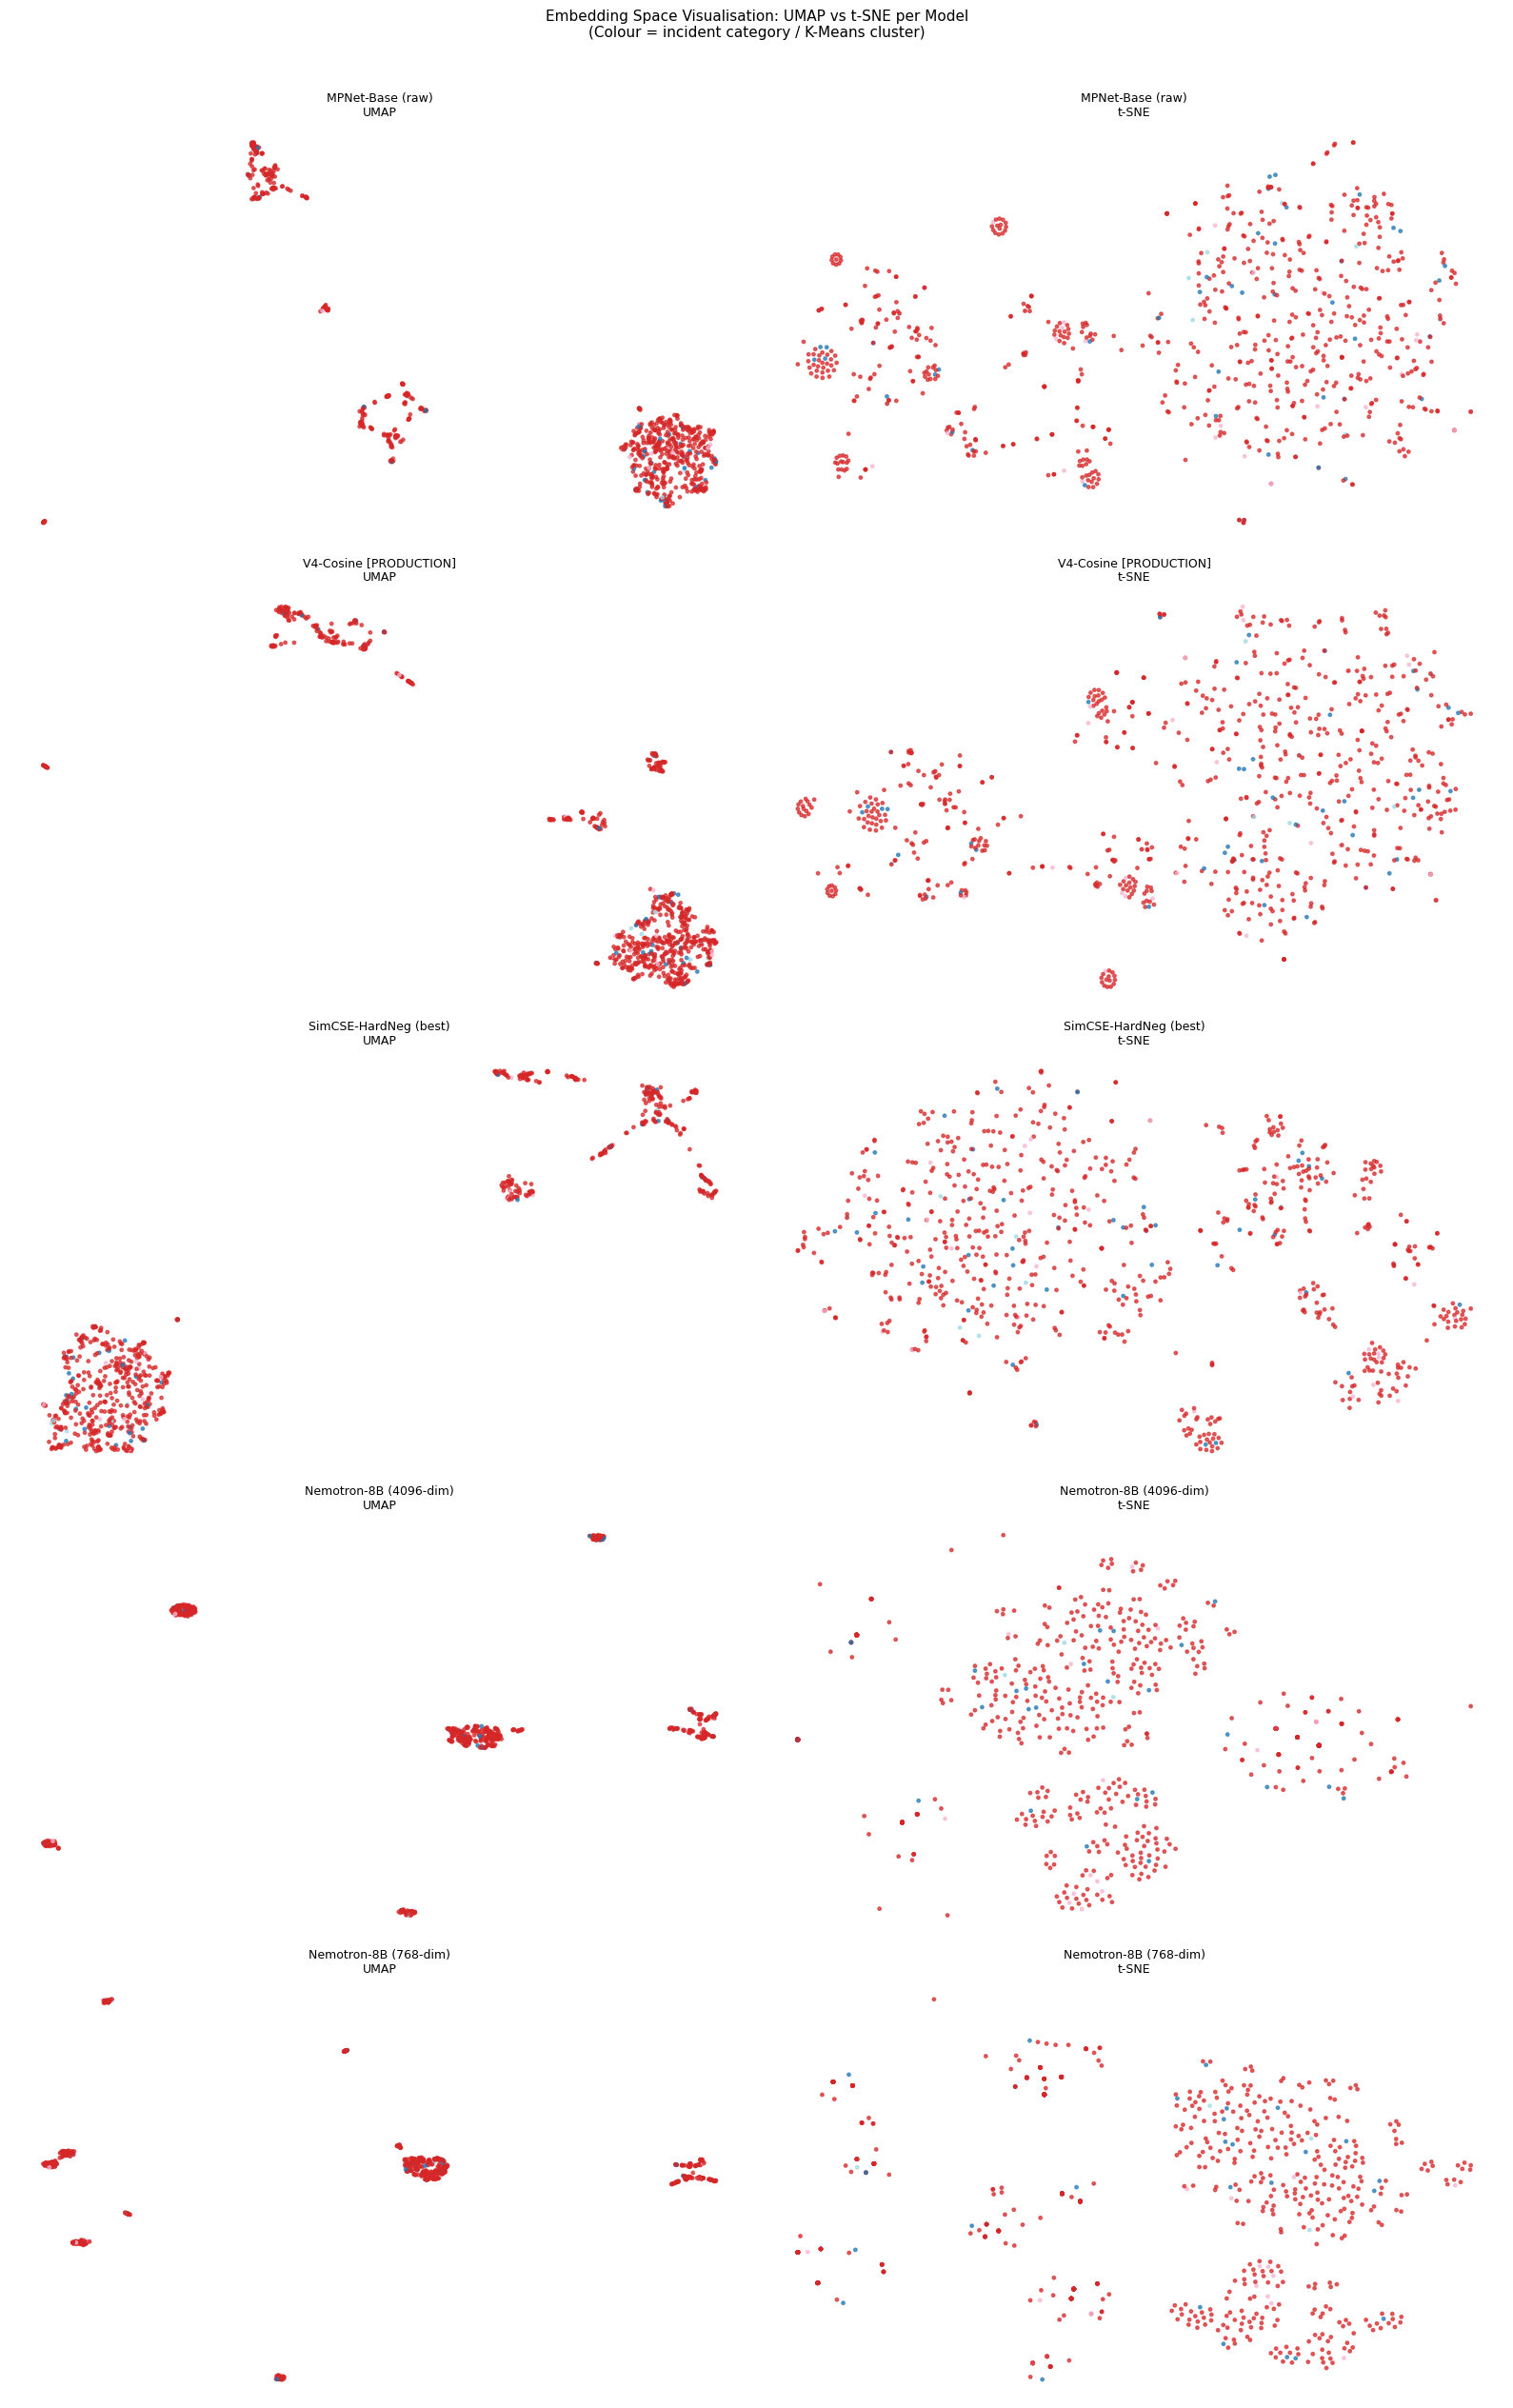

Saved: c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\results\nemotron_umap_tsne_comparison.png


In [20]:
try:
    import umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False
    print("umap-learn not installed. Run: pip install umap-learn")

from sklearn.manifold import TSNE

# Show 2D scatter for key models only (keep plot manageable)
VIZ_MODELS  = [
    'MPNet-Base (raw)',
    'V4-Cosine [PRODUCTION]',
    'SimCSE-HardNeg (best)',
    'Nemotron-8B (4096-dim)',
    'Nemotron-8B (768-dim)',
]
viz_models_avail = [m for m in VIZ_MODELS if m in all_embeddings
                    and all_embeddings[m].get('cluster_emb') is not None]

if not viz_models_avail:
    print("No embeddings available for visualization — skipping.")
else:
    n_models = len(viz_models_avail)
    n_cols   = 2
    n_rows   = n_models  # one row per model: left=UMAP, right=t-SNE

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5 * n_rows))
    if n_rows == 1:
        axes = [axes]

    # Colour by category label if available, else by KMeans cluster
    for row_idx, mname in enumerate(viz_models_avail):
        emb = all_embeddings[mname]['cluster_emb']
        # PCA pre-reduction for UMAP / t-SNE speed
        pca_50 = PCA(n_components=min(50, emb.shape[1], emb.shape[0]-1),
                     random_state=RANDOM_SEED)
        emb_50 = pca_50.fit_transform(emb)

        # Colour
        if cluster_labels_true is not None:
            color_labels = cluster_labels_true
            cmap = 'tab20'
        elif mname in cluster_results and 'kmeans' in cluster_results[mname]:
            km_tmp = KMeans(n_clusters=KMEANS_K, random_state=RANDOM_SEED, n_init=5)
            color_labels = km_tmp.fit_predict(emb_50)
            cmap = 'tab10'
        else:
            color_labels = np.zeros(len(emb), dtype=int)
            cmap = 'tab10'

        # ── UMAP ──────────────────────────────────────────────────────────
        ax_l = axes[row_idx][0]
        if UMAP_AVAILABLE:
            try:
                reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1,
                                    metric='cosine', random_state=RANDOM_SEED)
                xy = reducer.fit_transform(emb_50)
                sc = ax_l.scatter(xy[:, 0], xy[:, 1], c=color_labels,
                                  cmap=cmap, s=6, alpha=0.7)
                ax_l.set_title(f'{mname}\nUMAP', fontsize=9)
            except Exception as e:
                ax_l.text(0.5, 0.5, f'UMAP failed:\n{e}', ha='center', va='center',
                          transform=ax_l.transAxes, fontsize=8)
        else:
            ax_l.text(0.5, 0.5, 'umap-learn not installed', ha='center', va='center',
                      transform=ax_l.transAxes)
        ax_l.axis('off')

        # ── t-SNE ─────────────────────────────────────────────────────────
        ax_r = axes[row_idx][1]
        try:
            tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_SEED,
                        learning_rate='auto', init='pca', n_jobs=-1)
            xy_t = tsne.fit_transform(emb_50)
            ax_r.scatter(xy_t[:, 0], xy_t[:, 1], c=color_labels,
                         cmap=cmap, s=6, alpha=0.7)
            ax_r.set_title(f'{mname}\nt-SNE', fontsize=9)
        except Exception as e:
            ax_r.text(0.5, 0.5, f't-SNE failed:\n{e}', ha='center', va='center',
                      transform=ax_r.transAxes, fontsize=8)
        ax_r.axis('off')

    plt.suptitle('Embedding Space Visualisation: UMAP vs t-SNE per Model\n'
                 '(Colour = incident category / K-Means cluster)', fontsize=11, y=1.01)
    plt.tight_layout()
    viz_path = RESULTS_DIR / 'nemotron_umap_tsne_comparison.png'
    plt.savefig(viz_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {viz_path}")


## 9. Cross-Model Performance Comparison Table & Heatmap

FULL MODEL COMPARISON (sorted by ROC-AUC ↓)
                          Spearman  ROC-AUC     F1  Precision  Recall  Adv-AUC  Latency (ms)   Dim Status
Model                                                                                                    
MPNet-Base (raw)            0.5038   0.7909 0.7227     0.5664  0.9980   0.9900        3.0728   768     OK
V4-Cosine [PRODUCTION]      0.4949   0.7857 0.7134     0.6290  0.8240   0.9814        2.8855   768     OK
MPNet-LoRA Phase3-Only      0.4905   0.7832 0.7170     0.7221  0.7120   0.9715        2.9710   768     OK
MiniLM-L6-v2                0.4517   0.7608 0.7189     0.6667  0.7800   0.9543        0.9732   384     OK
SimCSE-HardNeg (best)       0.4241   0.7449 0.6948     0.6106  0.8060   0.9379        2.1277   768     OK
EmbeddingGemma-300M         0.3872   0.7236 0.6767     0.5140  0.9900   0.9130       18.7817   768     OK
MPNet-LoRA MNRL-2322        0.3818   0.7204 0.6890     0.5295  0.9860   0.9303        2.9098   768     OK
Si

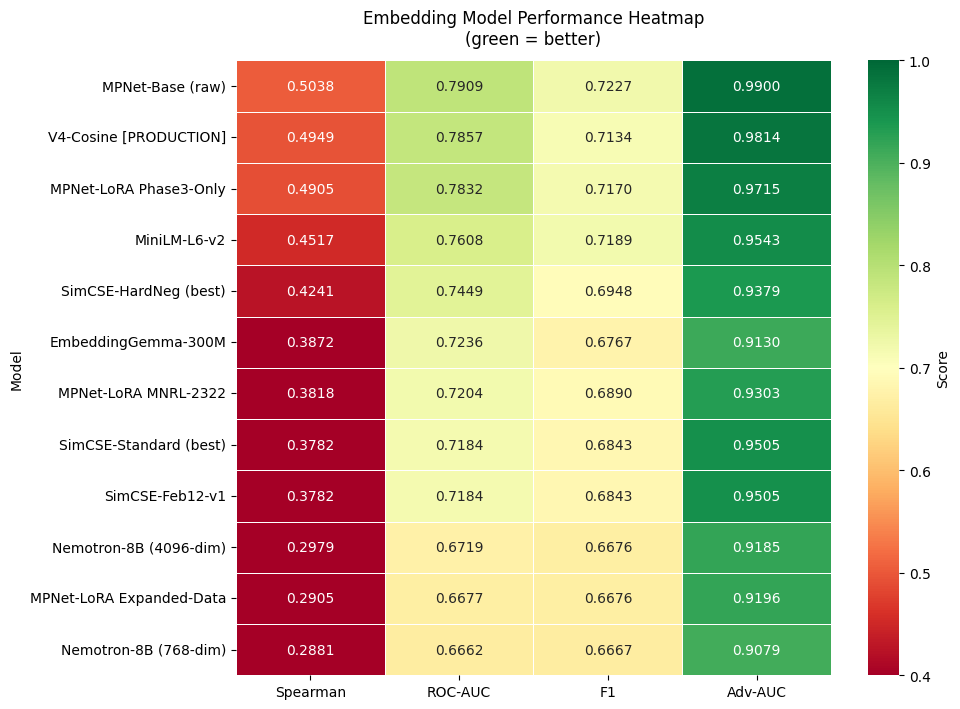


Saved heatmap: c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\results\nemotron_performance_heatmap.png


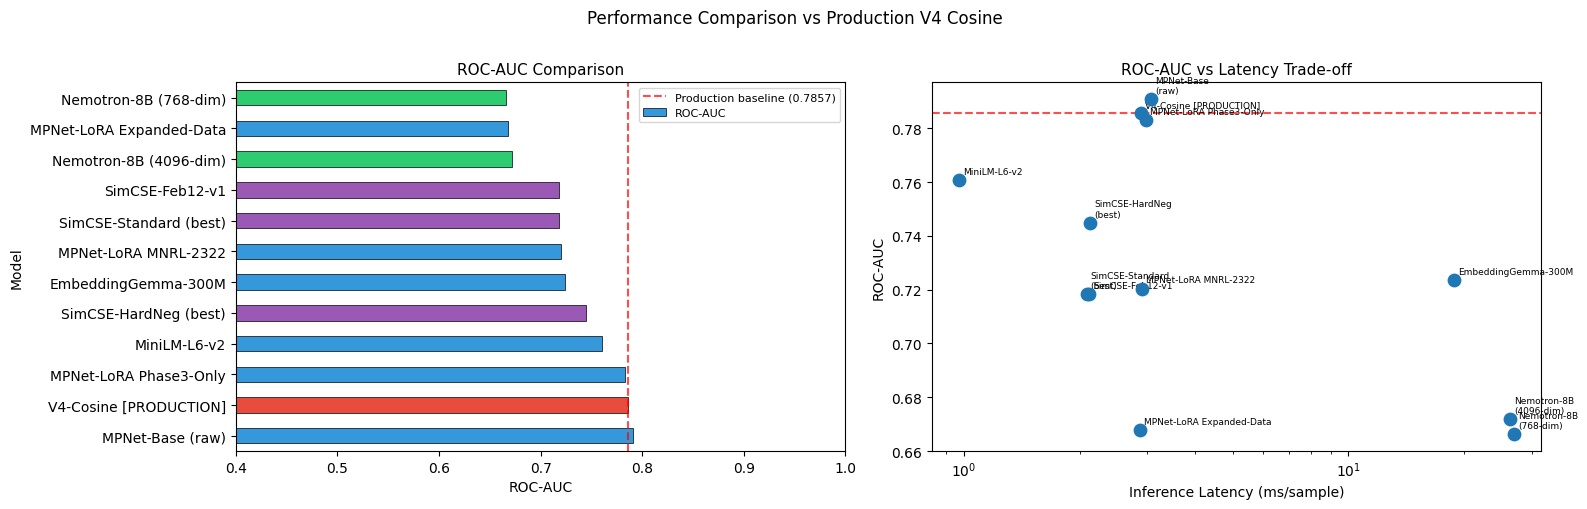

Saved bar chart: c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\results\nemotron_roc_latency_comparison.png


In [21]:
# ── Build master comparison DataFrame ────────────────────────────────────────
KEY_METRICS = ['spearman', 'roc_auc', 'f1', 'precision', 'recall',
               'adversarial_roc_auc', 'latency_ms_mean', 'embedding_dim']

rows = []
for mname, res in all_results.items():
    if 'error' in res:
        row = {'Model': mname, **{k: float('nan') for k in KEY_METRICS}}
        row['Status'] = f"FAILED: {res['error'][:60]}"
    else:
        row = {'Model': mname}
        for k in KEY_METRICS:
            row[k] = res.get(k, float('nan'))
        row['Status'] = 'OK'
    rows.append(row)

df_cmp = pd.DataFrame(rows).set_index('Model')
df_cmp = df_cmp.sort_values('roc_auc', ascending=False)

# Rename columns for display
df_display = df_cmp[KEY_METRICS + ['Status']].rename(columns={
    'spearman': 'Spearman',
    'roc_auc': 'ROC-AUC',
    'f1': 'F1',
    'precision': 'Precision',
    'recall': 'Recall',
    'adversarial_roc_auc': 'Adv-AUC',
    'latency_ms_mean': 'Latency (ms)',
    'embedding_dim': 'Dim',
})

# Baseline values for delta calculation
prod_name = PRODUCTION_BASELINE
prod_roc   = df_cmp.loc[prod_name, 'roc_auc'] if prod_name in df_cmp.index else float('nan')
prod_spear = df_cmp.loc[prod_name, 'spearman'] if prod_name in df_cmp.index else float('nan')

print("=" * 90)
print("FULL MODEL COMPARISON (sorted by ROC-AUC ↓)")
print("=" * 90)
with pd.option_context('display.float_format', '{:.4f}'.format, 'display.max_columns', 20):
    print(df_display.to_string())

# ── Heatmap of core metrics ───────────────────────────────────────────────────
metric_cols = ['Spearman', 'ROC-AUC', 'F1', 'Adv-AUC']
df_heat = df_display[metric_cols].copy().astype(float)

fig, ax = plt.subplots(figsize=(10, max(6, len(df_heat) * 0.6)))
hm = sns.heatmap(
    df_heat,
    annot=True,
    fmt='.4f',
    cmap='RdYlGn',
    vmin=0.4, vmax=1.0,
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'Score'},
)
ax.set_title('Embedding Model Performance Heatmap\n(green = better)', fontsize=12, pad=12)
plt.tight_layout()
hm_path = RESULTS_DIR / 'nemotron_performance_heatmap.png'
plt.savefig(hm_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"\nSaved heatmap: {hm_path}")

# ── Bar chart: ROC-AUC comparison ────────────────────────────────────────────
fig2, axes2 = plt.subplots(1, 2, figsize=(16, max(5, len(df_display) * 0.4)))

colors = []
for name in df_display.index:
    if name == prod_name:
        colors.append('#e74c3c')  # red = production
    elif 'Nemotron' in name:
        colors.append('#2ecc71')  # green = challenger
    elif 'SimCSE' in name:
        colors.append('#9b59b6')  # purple = unsupervised
    else:
        colors.append('#3498db')  # blue = baseline

# ROC-AUC bar
df_display['ROC-AUC'].dropna().plot(kind='barh', ax=axes2[0], color=colors, edgecolor='black', linewidth=0.5)
axes2[0].axvline(x=prod_roc, color='red', linestyle='--', alpha=0.7, label=f'Production baseline ({prod_roc:.4f})')
axes2[0].set_title('ROC-AUC Comparison', fontsize=11)
axes2[0].set_xlabel('ROC-AUC')
axes2[0].legend(fontsize=8)
axes2[0].set_xlim(0.4, 1.0)

# Latency vs ROC-AUC scatter
latencies = df_cmp['latency_ms_mean'].dropna()
roc_aucs  = df_cmp.loc[latencies.index, 'roc_auc'].dropna()
common    = latencies.index.intersection(roc_aucs.index)
axes2[1].scatter(latencies[common], roc_aucs[common], s=80, zorder=5)
for nm in common:
    axes2[1].annotate(nm.replace(' (', '\n('), (latencies[nm], roc_aucs[nm]),
                      fontsize=6.5, ha='left', va='bottom', xytext=(3, 3),
                      textcoords='offset points')
axes2[1].axhline(y=prod_roc, color='red', linestyle='--', alpha=0.7)
axes2[1].set_xlabel('Inference Latency (ms/sample)')
axes2[1].set_ylabel('ROC-AUC')
axes2[1].set_title('ROC-AUC vs Latency Trade-off', fontsize=11)
axes2[1].set_xscale('log')

plt.suptitle('Performance Comparison vs Production V4 Cosine', fontsize=12, y=1.01)
plt.tight_layout()
bar_path = RESULTS_DIR / 'nemotron_roc_latency_comparison.png'
plt.savefig(bar_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved bar chart: {bar_path}")


## 10. Clustering Quality Summary (Silhouette, Davies-Bouldin, ARI, NMI)

CLUSTERING QUALITY by Model & Algorithm
                   Model              Algorithm  K  Silhouette  Davies-Bouldin    ARI   NMI  Noise%  Time (s)
        MPNet-Base (raw)                 kmeans 10       0.126           2.801  0.004 0.017     NaN     0.086
        MPNet-Base (raw)                 dbscan  7       0.332             NaN  0.064   NaN   0.532     0.050
        MPNet-Base (raw)                hdbscan  9       0.498             NaN -0.001   NaN   0.715     0.108
        MPNet-Base (raw)     agglomerative_ward 10       0.117             NaN  0.007   NaN     NaN     0.015
        MPNet-Base (raw)  agglomerative_average 10       0.105             NaN  0.017   NaN     NaN     0.016
        MPNet-Base (raw) agglomerative_complete 10       0.160             NaN  0.009   NaN     NaN     0.015
            MiniLM-L6-v2                 kmeans 10       0.088           3.130  0.004 0.023     NaN     0.084
            MiniLM-L6-v2                 dbscan  5       0.356             NaN  

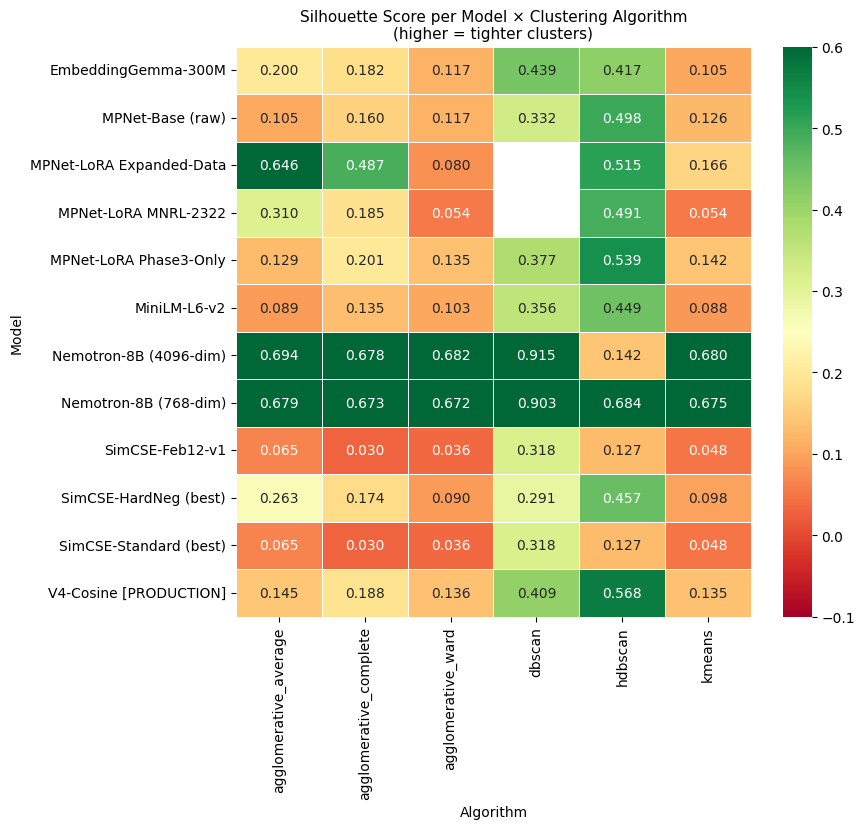

Saved: c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\results\nemotron_clustering_heatmap.png


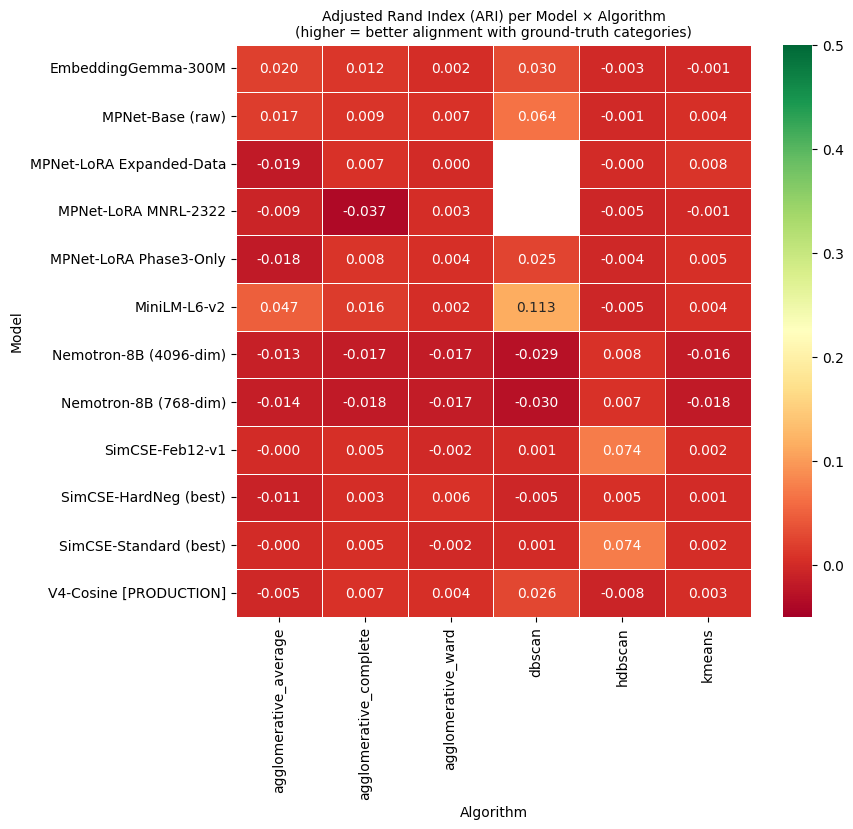

Saved: c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\results\nemotron_ari_heatmap.png


In [22]:
if not cluster_results:
    print("No clustering results to display.")
else:
    cluster_rows = []
    for mname, algos in cluster_results.items():
        for algo, cmetrics in algos.items():
            cluster_rows.append({
                'Model':     mname,
                'Algorithm': algo,
                'K':         cmetrics.get('n_clusters', '—'),
                'Silhouette': cmetrics.get('silhouette', float('nan')),
                'Davies-Bouldin': cmetrics.get('davies_bouldin', float('nan')),
                'ARI':       cmetrics.get('ari', float('nan')),
                'NMI':       cmetrics.get('nmi', float('nan')),
                'Noise%':    cmetrics.get('noise_ratio', float('nan')),
                'Time (s)':  cmetrics.get('time', float('nan')),
            })

    df_cluster_cmp = pd.DataFrame(cluster_rows)

    with pd.option_context('display.float_format', '{:.3f}'.format, 'display.max_rows', 100):
        print("CLUSTERING QUALITY by Model & Algorithm")
        print("=" * 90)
        print(df_cluster_cmp.to_string(index=False))

    # ── Heatmap: Silhouette per model per algorithm ───────────────────────────
    pivot = df_cluster_cmp.pivot_table(
        index='Model', columns='Algorithm', values='Silhouette', aggfunc='mean'
    )

    fig, ax = plt.subplots(figsize=(max(8, len(pivot.columns)*1.5), max(5, len(pivot)*0.7)))
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap='RdYlGn',
                vmin=-0.1, vmax=0.6, linewidths=0.5, ax=ax)
    ax.set_title('Silhouette Score per Model × Clustering Algorithm\n(higher = tighter clusters)',
                 fontsize=11)
    plt.tight_layout()
    clust_hm_path = RESULTS_DIR / 'nemotron_clustering_heatmap.png'
    plt.savefig(clust_hm_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {clust_hm_path}")

    # ── ARI heatmap ───────────────────────────────────────────────────────────
    if df_cluster_cmp['ARI'].notna().any():
        pivot_ari = df_cluster_cmp.pivot_table(
            index='Model', columns='Algorithm', values='ARI', aggfunc='mean'
        )
        fig2, ax2 = plt.subplots(figsize=(max(8, len(pivot_ari.columns)*1.5), max(5, len(pivot_ari)*0.7)))
        sns.heatmap(pivot_ari, annot=True, fmt='.3f', cmap='RdYlGn',
                    vmin=-0.05, vmax=0.5, linewidths=0.5, ax=ax2)
        ax2.set_title('Adjusted Rand Index (ARI) per Model × Algorithm\n(higher = better alignment with ground-truth categories)',
                      fontsize=10)
        plt.tight_layout()
        ari_path = RESULTS_DIR / 'nemotron_ari_heatmap.png'
        plt.savefig(ari_path, dpi=150, bbox_inches='tight')
        plt.show()
        print(f"Saved: {ari_path}")


## 11. Production Decision Matrix & Save Results

In [23]:
"""
Decision criteria for replacing V4 Cosine with Nemotron (or any other model):
  - ROC-AUC improvement >= 2%  (hard threshold)
  - Spearman improvement >= 2%
  - Latency <= 50ms/sample     (still within API 500ms SLA with padding)
  - Adversarial AUC maintained or improved
"""

THRESHOLDS = {
    'roc_auc_min_improvement':   0.02,
    'spearman_min_improvement':  0.02,
    'max_latency_ms':            50.0,
}

print("=" * 80)
print("    PRODUCTION DECISION MATRIX")
print("=" * 80)

# Production baseline values
if prod_name not in df_cmp.index:
    print(f"ERROR: Production model '{prod_name}' not found in results!")
else:
    prod_roc_auc   = df_cmp.loc[prod_name, 'roc_auc']
    prod_spearman  = df_cmp.loc[prod_name, 'spearman']
    prod_latency   = df_cmp.loc[prod_name, 'latency_ms_mean']
    prod_adv       = df_cmp.loc[prod_name, 'adversarial_roc_auc']

    print(f"\n  Production baseline ({prod_name}):")
    print(f"    ROC-AUC:       {prod_roc_auc:.4f}")
    print(f"    Spearman:      {prod_spearman:.4f}")
    print(f"    Adv-AUC:       {prod_adv:.4f}")
    print(f"    Latency:       {prod_latency:.2f} ms/sample")
    print(f"\n  Criteria to beat:")
    print(f"    ROC-AUC >=     {prod_roc_auc + THRESHOLDS['roc_auc_min_improvement']:.4f}  (+{THRESHOLDS['roc_auc_min_improvement']*100:.0f}%)")
    print(f"    Spearman >=    {prod_spearman + THRESHOLDS['spearman_min_improvement']:.4f}  (+{THRESHOLDS['spearman_min_improvement']*100:.0f}%)")
    print(f"    Latency <=     {THRESHOLDS['max_latency_ms']:.1f} ms/sample")
    print()

    decision_rows = []
    for mname in df_cmp.index:
        if mname == prod_name:
            continue
        row = df_cmp.loc[mname]
        if pd.isna(row['roc_auc']):
            verdict = '⚠  FAILED'
            action  = 'Model could not be evaluated'
        else:
            roc_ok     = row['roc_auc']  >= prod_roc_auc  + THRESHOLDS['roc_auc_min_improvement']
            spear_ok   = row['spearman'] >= prod_spearman + THRESHOLDS['spearman_min_improvement']
            latency_ok = row['latency_ms_mean'] <= THRESHOLDS['max_latency_ms']
            adv_ok     = pd.isna(row['adversarial_roc_auc']) or row['adversarial_roc_auc'] >= prod_adv - 0.01

            delta_roc  = row['roc_auc']  - prod_roc_auc
            delta_sp   = row['spearman'] - prod_spearman

            if roc_ok and spear_ok and latency_ok:
                verdict = '✅ REPLACE — upgrade recommended'
                if delta_roc >= 0.05:
                    action = 'HIGH PRIORITY: >5% ROC-AUC gain'
                else:
                    action = 'Moderate gain — validate with A/B test first'
            elif roc_ok and not latency_ok:
                verdict = '⚡ MAYBE — better accuracy but too slow'
                action  = f'Consider quantisation; latency {row["latency_ms_mean"]:.1f} ms > {THRESHOLDS["max_latency_ms"]} ms'
            elif latency_ok and not roc_ok:
                verdict = '❌ KEEP V4 — no meaningful accuracy gain'
                action  = f'Δ ROC-AUC={delta_roc:+.4f} — not enough to justify switch'
            else:
                verdict = '❌ KEEP V4 — worse on both'
                action  = f'Δ ROC-AUC={delta_roc:+.4f}  Δ Spearman={delta_sp:+.4f}'

        decision_rows.append({
            'Model':        mname,
            'Δ ROC-AUC':    f"{row['roc_auc'] - prod_roc_auc:+.4f}",
            'Δ Spearman':   f"{row['spearman'] - prod_spearman:+.4f}",
            'Latency (ms)': f"{row['latency_ms_mean']:.2f}",
            'Adv-AUC':      f"{row['adversarial_roc_auc']:.4f}",
            'Verdict':      verdict,
            'Action':       action,
        })

    df_dec = pd.DataFrame(decision_rows).set_index('Model')
    with pd.option_context('display.max_colwidth', 60):
        print(df_dec.to_string())

# ── Save all results to JSON ──────────────────────────────────────────────────
ts = datetime.now().strftime('%Y%m%d_%H%M%S')
out = {
    'timestamp':           ts,
    'production_baseline': prod_name,
    'thresholds':          THRESHOLDS,
    'supervised_results':  {k: {m: v for m, v in res.items()
                                if m != 'confusion_matrix'}   # skip large matrix for JSON
                             for k, res in all_results.items()},
    'decisions':           df_dec.reset_index().to_dict(orient='records'),
    'latency_benchmark':   latency_records,
}
out_path = RESULTS_DIR / f'nemotron_full_evaluation_{ts}.json'
with open(out_path, 'w') as f:
    json.dump(out, f, indent=2, default=str)
print(f"\nFull results saved: {out_path}")

# ── Final verdict summary ─────────────────────────────────────────────────────
print("\n" + "=" * 80)
print("  SUMMARY")
print("=" * 80)
best_overall = df_cmp['roc_auc'].idxmax()
print(f"  Best ROC-AUC:   {best_overall}  ({df_cmp.loc[best_overall, 'roc_auc']:.4f})")
best_spear   = df_cmp['spearman'].idxmax()
print(f"  Best Spearman:  {best_spear}  ({df_cmp.loc[best_spear, 'spearman']:.4f})")
fastest      = df_cmp['latency_ms_mean'].idxmin()
print(f"  Fastest:        {fastest}  ({df_cmp.loc[fastest, 'latency_ms_mean']:.2f} ms/sample)")

nemotron_4096 = 'Nemotron-8B (4096-dim)'
nemotron_768  = 'Nemotron-8B (768-dim)'
if nemotron_4096 in df_cmp.index and nemotron_768 in df_cmp.index:
    n4_roc  = df_cmp.loc[nemotron_4096, 'roc_auc']
    n7_roc  = df_cmp.loc[nemotron_768,  'roc_auc']
    n4_lat  = df_cmp.loc[nemotron_4096, 'latency_ms_mean']
    n7_lat  = df_cmp.loc[nemotron_768,  'latency_ms_mean']
    print(f"\n  Nemotron-8B 4096-dim: ROC-AUC={n4_roc:.4f}  Latency={n4_lat:.2f} ms")
    print(f"  Nemotron-8B  768-dim: ROC-AUC={n7_roc:.4f}  Latency={n7_lat:.2f} ms")
    dim_loss = n4_roc - n7_roc
    print(f"  Truncation cost: {dim_loss:+.4f} ROC-AUC (768-dim vs 4096-dim)")
print("=" * 80)


    PRODUCTION DECISION MATRIX

  Production baseline (V4-Cosine [PRODUCTION]):
    ROC-AUC:       0.7857
    Spearman:      0.4949
    Adv-AUC:       0.9814
    Latency:       2.89 ms/sample

  Criteria to beat:
    ROC-AUC >=     0.8057  (+2%)
    Spearman >=    0.5149  (+2%)
    Latency <=     50.0 ms/sample

                         Δ ROC-AUC Δ Spearman Latency (ms) Adv-AUC                                  Verdict                                            Action
Model                                                                                                                                                        
MPNet-Base (raw)           +0.0051    +0.0089         3.07  0.9900  ❌ KEEP V4 — no meaningful accuracy gain  Δ ROC-AUC=+0.0051 — not enough to justify switch
MPNet-LoRA Phase3-Only     -0.0025    -0.0044         2.97  0.9715  ❌ KEEP V4 — no meaningful accuracy gain  Δ ROC-AUC=-0.0025 — not enough to justify switch
MiniLM-L6-v2               -0.0250    -0.0432         

## 12. HuggingFace Authentication (Required for Nemotron-8B Download)

In [24]:
"""
⚠️  RUN THIS CELL BEFORE CELL 6 (Main Evaluation Loop)
   Nemotron-8B requires a HuggingFace account with model access.

Steps:
  1. Accept nvidia terms at: https://huggingface.co/nvidia/llama-embed-nemotron-8b
  2. Create token at: https://huggingface.co/settings/tokens
  3. Add to .env file: HUGGINGFACE_TOKEN=hf_xxxx
"""
from huggingface_hub import login
from dotenv import load_dotenv
import os

load_dotenv()
load_dotenv(Path.home() / '.env')

token = os.getenv('HUGGINGFACE_TOKEN')
if token:
    login(token=token)
    print("✓ HuggingFace authenticated")
else:
    print("⚠  No token found. Set HUGGINGFACE_TOKEN in .env")
    print("   Or uncomment below for interactive login:")
    # login()  # interactive


✓ HuggingFace authenticated
